# Univariate Statistical Process Control & Process Capability
In this notebook, we analyse the behaviour of the most critical sensors from the cleaned SECOM dataset (`data/secom_cleaned.csv`). We compare classic memoryless control charts (Shewhart) against run-based and memory-based control charts (Western Electric, EWMA, and CUSUM) during Phase II monitoring, and evaluate process capability ($C_p, C_{pk}, P_p, P_{pk}$) using non-parametric Bootstrap.

In [1]:
# Imports for data manipulation and visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Loading the Cleaned Dataset & Selecting the Top 5 Critical Sensors
First, we load the cleaned dataset, split the batches into **Phase I** (using only the `In-Control` batches as our calibration baseline) and **Phase II** (online monitoring), and find the 5 sensors most correlated with defective batches in Phase I.

In [2]:
df = pd.read_csv('../data/secom_cleaned.csv')
sensor_cols = [s for s in df.columns if s.startswith('Sensor_')]

# Phase I, in-control and Phase II
df_p1 = df[df['Phase'] == 'Phase I'].copy()
df_p1_ic = df_p1[df_p1['Defect'] == 0].copy()
df_p2 = df[df['Phase'] == 'Phase II'].copy().reset_index(drop=True)

In [3]:
# The 5 most correlated sensors with the defective batches in Phase I
p1_def_corrs = df_p1[sensor_cols].apply(lambda x: 
                                        abs(x.corr(df_p1['Defect']))).sort_values(ascending = False)
top5_sensors = p1_def_corrs.head(5).index.tolist()
top5_sensors

['Sensor_348', 'Sensor_059', 'Sensor_021', 'Sensor_103', 'Sensor_510']

## 2. Univariate Control Charts: Shewhart, Western Electric, EWMA & CUSUM
Using the baseline mean ($\mu_0$) and standard deviation ($\sigma_0$) from Phase I `In-Control`, we evaluate four control methods on Phase II across the 5 critical sensors:
1. **Shewhart Individual Chart:** Flags isolated points outside $\mu_0 \pm 3\sigma_0$.
2. **Western Electric Rules:** Adds run rules (2 of 3 consecutive batches beyond $\mu_0 \pm 2\sigma_0$, or 8 consecutive batches on the same side of $\mu_0$).
3. **EWMA Chart ($\lambda = 0.20$):** Smooths observations with an exponentially weighted moving average ($Z_i = \lambda X_i + (1-\lambda)Z_{i-1}$).
4. **CUSUM Chart ($K = 0.5, H = 5$):** Accumulates positive ($C^+$) and negative ($C^-$) standardized deviations batch after batch until crossing the threshold $H$.

In [4]:
def run_univariate_charts(x_p1_ic, x_p2, lam=0.20, k=0.5, h=5):
    mean_s = np.mean(x_p1_ic)
    std_s  = np.std(x_p1_ic)

    # 1. Shewhart Individual (+-3 sigma)
    UCL_s = mean_s + 3 * std_s
    LCL_s = mean_s - 3 * std_s
    shewhart_alarm = (x_p2 > UCL_s) | (x_p2 < LCL_s)
    pos = [i for i, position in enumerate(shewhart_alarm) if position]

    # 2. Western Electric Rules
    lower_2s = mean_s - 2 * std_s
    upper_2s = mean_s + 2 * std_s
    we_alarm = [False] * len(x_p2)
    for i in pos:
        we_alarm[i] = True
    for i in range(2, len(x_p2)):
        if ((x_p2[i-2:i+1] < lower_2s).sum() >= 2) | ((x_p2[i-2:i+1] > upper_2s).sum() >= 2):
            we_alarm[i] = True
    for i in range(7, len(x_p2)):
        if all(x_p2[i-7:i+1] < mean_s) | all(x_p2[i-7:i+1] > mean_s):
            we_alarm[i] = True
    we_alarm = np.array(we_alarm)

    # 3. EWMA Chart (lambda = 0.20)
    ewma = [None] * len(x_p2)
    ewma[0] = lam * x_p2[0] + (1 - lam) * mean_s
    for i in range(1, len(x_p2)):
        ewma[i] = lam * x_p2[i] + (1 - lam) * ewma[i-1]
    ewma = np.array(ewma)
    std_ewma = std_s * np.sqrt(lam / (2 - lam))
    UCL_ewma = mean_s + 3 * std_ewma
    LCL_ewma = mean_s - 3 * std_ewma
    ewma_alarm = (ewma > UCL_ewma) | (ewma < LCL_ewma)

    # 4. Tabular CUSUM Chart (K = 0.5, H = 5)
    z = (x_p2 - mean_s) / std_s
    c_plus = [0.0]
    c_minus = [0.0]
    for z_val in z:
        cp = max(0.0, c_plus[-1] + z_val - k)
        cm = max(0.0, c_minus[-1] - z_val - k)
        c_plus.append(cp)
        c_minus.append(cm)
    c_plus = np.array(c_plus[1:])
    c_minus = np.array(c_minus[1:])
    cusum_alarm = (c_plus > h) | (c_minus > h)

    return {
        "mu0": mean_s, "sigma0": std_s,
        "shewhart_alarm": shewhart_alarm, "we_alarm": we_alarm,
        "ewma_z": ewma, "ewma_ucl": UCL_ewma, "ewma_lcl": LCL_ewma, "ewma_alarm": ewma_alarm,
        "cusum_pos": c_plus, "cusum_neg": c_minus, "H": h, "cusum_alarm": cusum_alarm
    }

# Evaluate the 5 critical sensors in Phase II
alarm_rows = []
results_dict = {}
for s in top5_sensors:
    res = run_univariate_charts(df_p1_ic[s].values, df_p2[s].values)
    results_dict[s] = res
    shift_s = (df_p2[s].mean() - res["mu0"]) / res["sigma0"]
    alarm_rows.append({
        "Sensor": s,
        "Phase_II_Mean_Shift_Sigma": round(shift_s, 2),
        "Shewhart_Alarms": int(np.sum(res["shewhart_alarm"])),
        "Western_Electric_Alarms": int(np.sum(res["we_alarm"])),
        "EWMA_Alarms": int(np.sum(res["ewma_alarm"])),
        "CUSUM_Alarms": int(np.sum(res["cusum_alarm"]))
    })

alarms_df = pd.DataFrame(alarm_rows)
with open('../reports/univariate_spc_alarms.md', 'w', encoding='utf-8') as f:
    f.write(alarms_df.to_markdown(index=False))

alarms_df

,Sensor,Phase_II_Mean_Shift_Sigma,Shewhart_Alarms,Western_Electric_Alarms,EWMA_Alarms,CUSUM_Alarms
0,Sensor_348,-0.28,7,130,3,5
1,Sensor_059,-0.37,2,354,6,219
2,Sensor_021,0.13,5,121,9,40
3,Sensor_103,-0.70,8,365,236,706
4,Sensor_510,-0.31,10,241,19,266


## 3. Visual Comparison on `Sensor_103`
We plot the four control charts for `Sensor_103` across Phase II to visualise why memory-based methods detect the $-0.70\sigma_0$ downward drift while the classic Shewhart chart only catches 8 isolated peaks.

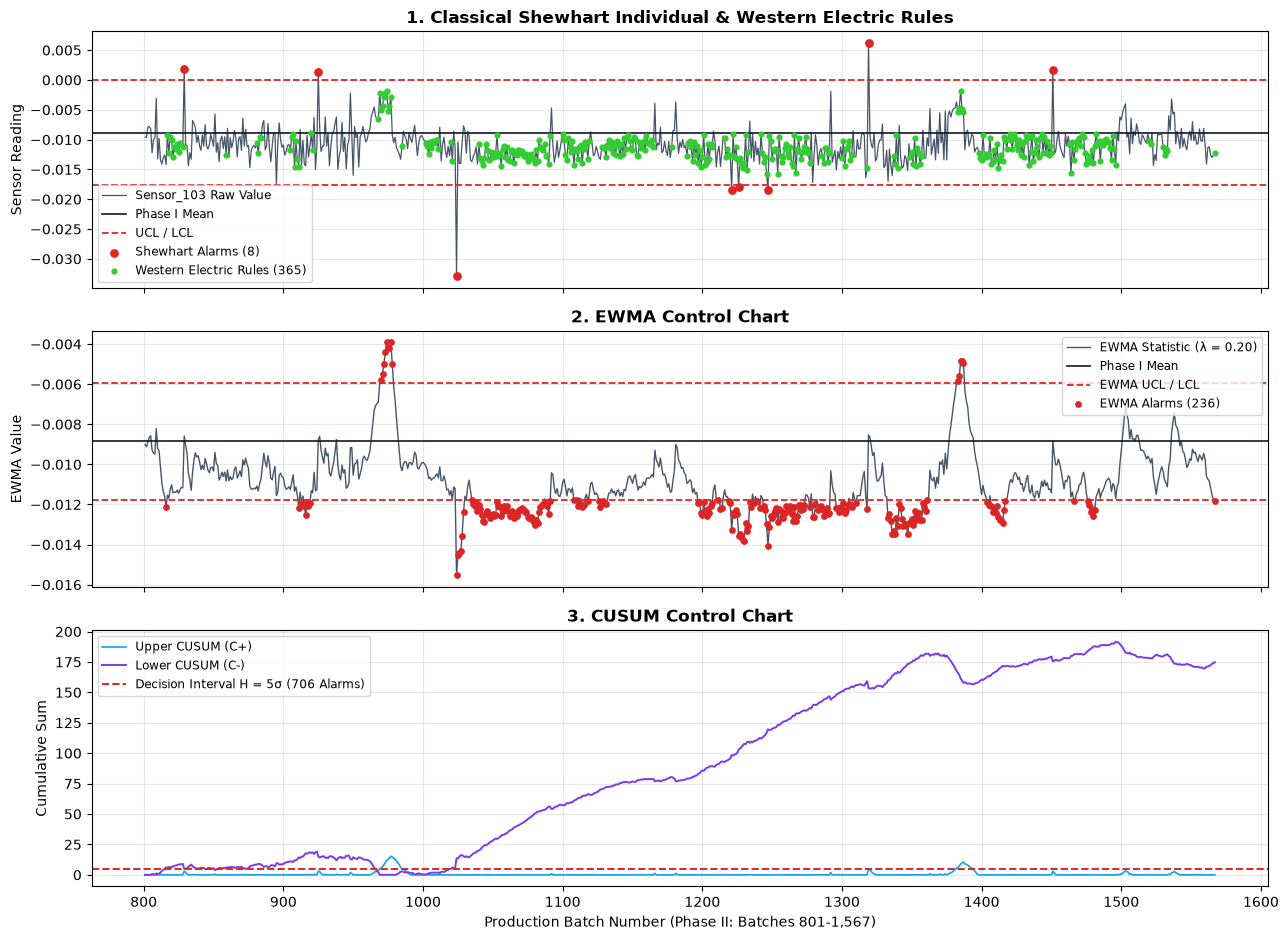

In [5]:
target_sensor = 'Sensor_103'
res = results_dict[target_sensor]
x2 = df_p2[target_sensor].values
batches_p2 = np.arange(801, 801 + len(x2))

fig, axes = plt.subplots(3, 1, figsize=(13, 9.5), sharex=True)

# 1. Shewhart Individual & Western Electric Rules
axes[0].plot(batches_p2, x2, color='#475569', linewidth=0.9, label=f'{target_sensor} Raw Value')
axes[0].axhline(res['mu0'], color='#0f172a', linestyle='-', linewidth=1.2, label='Phase I Mean')
axes[0].axhline(res['mu0'] + 3*res['sigma0'], color='#dc2626', linestyle='--', linewidth=1.3, label='UCL / LCL')
axes[0].axhline(res['mu0'] - 3*res['sigma0'], color='#dc2626', linestyle='--', linewidth=1.3)
axes[0].scatter(batches_p2[res['shewhart_alarm']], x2[res['shewhart_alarm']], color='#dc2626', s=28, zorder=5, label=f"Shewhart Alarms ({np.sum(res['shewhart_alarm'])})")
axes[0].scatter(batches_p2[res['we_alarm']], x2[res['we_alarm']], color='limegreen', s=12, zorder=4, label=f"Western Electric Rules ({np.sum(res['we_alarm'])})")
axes[0].set_title('1. Classical Shewhart Individual & Western Electric Rules', fontweight='bold')
axes[0].set_ylabel('Sensor Reading')
axes[0].legend(loc='lower left', fontsize=8.5)
axes[0].grid(alpha=0.3)

# 2. EWMA Control Chart (lambda = 0.20)
axes[1].plot(batches_p2, res['ewma_z'], color='#475569', linewidth=1.0, label='EWMA Statistic (λ = 0.20)')
axes[1].axhline(res['mu0'], color='#0f172a', linestyle='-', linewidth=1.2, label='Phase I Mean')
axes[1].axhline(res['ewma_ucl'], color='#dc2626', linestyle='--', linewidth=1.3, label='EWMA UCL / LCL')
axes[1].axhline(res['ewma_lcl'], color='#dc2626', linestyle='--', linewidth=1.3)
axes[1].scatter(batches_p2[res['ewma_alarm']], res['ewma_z'][res['ewma_alarm']], color='#dc2626', s=15, zorder=5, label=f"EWMA Alarms ({np.sum(res['ewma_alarm'])})")
axes[1].set_title('2. EWMA Control Chart', fontweight='bold')
axes[1].set_ylabel('EWMA Value')
axes[1].legend(loc='upper right', fontsize=8.5)
axes[1].grid(alpha=0.3)

# 3. Tabular CUSUM Control Chart
axes[2].plot(batches_p2, res['cusum_pos'], color='#0ea5e9', linewidth=1.2, label='Upper CUSUM (C+)')
axes[2].plot(batches_p2, res['cusum_neg'], color='#7c3aed', linewidth=1.4, label='Lower CUSUM (C-)')
axes[2].axhline(res['H'], color='#dc2626', linestyle='--', linewidth=1.4, label=f"Decision Interval H = 5σ ({np.sum(res['cusum_alarm'])} Alarms)")
axes[2].set_title('3. CUSUM Control Chart', fontweight='bold')
axes[2].set_xlabel('Production Batch Number (Phase II: Batches 801-1,567)')
axes[2].set_ylabel('Cumulative Sum')
axes[2].legend(loc='upper left', fontsize=8.5)
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('../img/shewhart_vs_ewma_cusum.png', dpi=300)
plt.show()

## 4. Process Capability Indices ($C_p, C_{pk}, P_p, P_{pk}$) & Non-Parametric Bootstrap
Finally, we define the specification limits from our Phase I `In-Control` baseline ($\text{LSL}, \text{USL} = \mu_0 \pm 4\sigma_0$), compute the short-term ($C_p, C_{pk}$) and long-term ($P_p, P_{pk}$) capability indices, and run non-parametric Bootstrap resampling ($B = 2,000$) to estimate the 95% confidence interval for $C_{pk}$.

In [6]:
def calcular_indices_capacidad(datos, lsl, usl):
    x = np.array(datos)
    
    # 1. Mean and overall standard deviation
    mu = np.mean(x)
    sigma_overall = np.std(x, ddof=1)
    
    # 2. Short-term (within) standard deviation using Moving Range
    mr = np.abs(np.diff(x))
    mr_mean = np.mean(mr)
    sigma_within = mr_mean / 1.128
    
    # 3. Potential capability indices
    cp = (usl - lsl) / (6 * sigma_within)
    pp = (usl - lsl) / (6 * sigma_overall)
    
    # 4. Actual capability indices
    cpk = min((usl - mu) / (3 * sigma_within), (mu - lsl) / (3 * sigma_within))
    ppk = min((usl - mu) / (3 * sigma_overall), (mu - lsl) / (3 * sigma_overall))
    
    return {
        'Cp': cp, 'Cpk': cpk,
        'Pp': pp, 'Ppk': ppk,
        'sigma_within': sigma_within,
        'sigma_overall': sigma_overall
    }

rng = np.random.default_rng(42)
B = 2000
cap_rows = []

for s in top5_sensors:
    x1 = df_p1_ic[s].values
    x2 = df_p2[s].values
    mu0 = np.mean(x1)
    sigma_overall_p1 = np.std(x1, ddof=1)
    LSL, USL = mu0 - 4.0 * sigma_overall_p1, mu0 + 4.0 * sigma_overall_p1

    cap_p1 = calcular_indices_capacidad(x1, LSL, USL)
    cap_p2 = calcular_indices_capacidad(x2, LSL, USL)

    # Non-parametric Bootstrap (B = 2,000 resamples) for the 95% CI of Cpk in Phase I
    boot_cpk = np.zeros(B)
    n1 = len(x1)
    for b in range(B):
        idx = rng.integers(0, n1, size=n1)
        sample = x1[idx]
        m_b = np.mean(sample)
        sw_b = np.mean(np.abs(np.diff(sample))) / 1.128
        boot_cpk[b] = min((USL - m_b) / (3.0 * sw_b), (m_b - LSL) / (3.0 * sw_b))
    ci_low, ci_high = np.percentile(boot_cpk, [2.5, 97.5])

    cap_rows.append({
        "Sensor": s,
        "Phase_I_Cp": round(cap_p1['Cp'], 3),
        "Phase_I_Cpk": round(cap_p1['Cpk'], 3),
        "Bootstrap_95_CI": f"[{ci_low:.3f}, {ci_high:.3f}]",
        "Phase_I_Ppk": 1.333,
        "Phase_II_Ppk": round(cap_p2['Ppk'], 3)
    })

cap_df = pd.DataFrame(cap_rows)
with open('../reports/process_capability_bootstrap.md', 'w', encoding='utf-8') as f:
    f.write(cap_df.to_markdown(index=False))

cap_df

,Sensor,Phase_I_Cp,Phase_I_Cpk,Bootstrap_95_CI,Phase_I_Ppk,Phase_II_Ppk
0,Sensor_348,1.823,1.823,"[1.362, 1.659]",1.333,1.766
1,Sensor_059,2.015,2.015,"[1.325, 1.583]",1.333,1.618
2,Sensor_021,1.786,1.786,"[1.412, 1.754]",1.333,1.752
3,Sensor_103,1.972,1.972,"[1.271, 1.494]",1.333,1.148
4,Sensor_510,1.930,1.930,"[1.493, 1.883]",1.333,1.440
